In [2]:
#Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score

In [3]:
#Read file

df = pd.read_csv('diabetes.csv')
df = df.drop(['CholCheck','Stroke',
              'HeartDiseaseorAttack','Fruits','Veggies','NoDocbcCost',
              'GenHlth','MentHlth','PhysHlth','DiffWalk','Education','Income'], axis = 1)

In [4]:
#Data cleaning - BMI outliers

Q1 = df['BMI'].quantile(0.25)
Q3 = df['BMI'].quantile(0.75)
IQR = Q3 - Q1

df = df[(df['BMI'] >= (Q1 - 1.5*IQR)) & (df['BMI'] <= (Q3 + 1.5*IQR))]

In [5]:
df.head()

,Diabetes_012,HighBP,HighChol,BMI,Smoker,PhysActivity,HvyAlcoholConsump,AnyHealthcare,Sex,Age
0,0.0,1.0,1.0,40.0,1.0,0.0,0.0,1.0,0.0,9.0
1,0.0,0.0,0.0,25.0,1.0,1.0,0.0,0.0,0.0,7.0
2,0.0,1.0,1.0,28.0,0.0,0.0,0.0,1.0,0.0,9.0
3,0.0,1.0,0.0,27.0,0.0,1.0,0.0,1.0,0.0,11.0
4,0.0,1.0,1.0,24.0,0.0,1.0,0.0,1.0,0.0,11.0


In [6]:
#Converting BMI numerical data into categories
# < 18.5 = underweight
# 18.5 <= x < 25 = healthy
# 25 <= x < 30 = overweight
# 30 <= x < 40 = obesity
# >= 40 = severe obesity

df['BMI'] = pd.cut(df['BMI'], bins=[0, 18.5, 25, 30, 40, 999], 
                   labels=['underweight', 'healthy', 'overweight', 'obesity', 'severe obesity'], 
                   right = False)

In [7]:
df.head()

,Diabetes_012,HighBP,HighChol,BMI,Smoker,PhysActivity,HvyAlcoholConsump,AnyHealthcare,Sex,Age
0,0.0,1.0,1.0,severe obesity,1.0,0.0,0.0,1.0,0.0,9.0
1,0.0,0.0,0.0,overweight,1.0,1.0,0.0,0.0,0.0,7.0
2,0.0,1.0,1.0,overweight,0.0,0.0,0.0,1.0,0.0,9.0
3,0.0,1.0,0.0,overweight,0.0,1.0,0.0,1.0,0.0,11.0
4,0.0,1.0,1.0,healthy,0.0,1.0,0.0,1.0,0.0,11.0


In [8]:
df.shape

(243833, 10)

In [9]:
proportion = df.groupby('Diabetes_012').size().reset_index(name = "count")
proportion['percentage'] = proportion['count'] / proportion['count'].sum()
proportion

,Diabetes_012,count,percentage
0,0.0,207514,0.851050
1,1.0,4340,0.017799
2,2.0,31979,0.131151


In [10]:
#Extracting features and labels

y = df['Diabetes_012']

X = df[df.columns]
X = df.drop(columns = ['Diabetes_012'])

In [11]:
#Converting BMI and Age to one_hot binary

X = pd.get_dummies(X, columns = ['BMI','Age'], dtype = int)
print(X.shape)
X.head()

(243833, 25)


,HighBP,HighChol,Smoker,PhysActivity,HvyAlcoholConsump,AnyHealthcare,Sex,BMI_underweight,BMI_healthy,BMI_overweight,...,Age_4.0,Age_5.0,Age_6.0,Age_7.0,Age_8.0,Age_9.0,Age_10.0,Age_11.0,Age_12.0,Age_13.0
0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
1,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0,0,1,...,0,0,0,1,0,0,0,0,0,0
2,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0,0,1,...,0,0,0,0,0,1,0,0,0,0
3,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
4,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0,1,0,...,0,0,0,0,0,0,0,1,0,0


In [12]:
# Train-Val-Test split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, random_state = 42)
X_train, X_valid, y_train, y_valid = train_test_split(X_train, y_train, test_size = 0.1176, random_state = 42)

print(X_train.shape, X_valid.shape, X_test.shape, y_train.shape, y_valid.shape, y_test.shape)

(182884, 25) (24374, 25) (36575, 25) (182884,) (24374,) (36575,)


In [13]:
tr_acc = [] #Storing training accuracies
val_acc = [] #Storing validation accuracies

In [14]:
#Decision Tree Classifier

clf = DecisionTreeClassifier(max_depth = 4, random_state = 42, class_weight = 'balanced')
clf.fit(X_train, y_train)


y_pred_tr = clf.predict(X_train)

In [15]:
def generate_confusion_matrix(y_true, y_pred):
    # visualize the confusion matrix
    ax = plt.subplot()
    c_mat = confusion_matrix(y_true, y_pred)
    sns.heatmap(c_mat, annot=True, fmt='g', ax=ax)

    ax.set_xlabel('Predicted labels', fontsize=15)
    ax.set_ylabel('True labels', fontsize=15)
    ax.set_title('Confusion Matrix', fontsize=15)

Prediction accuracy: 61.89%


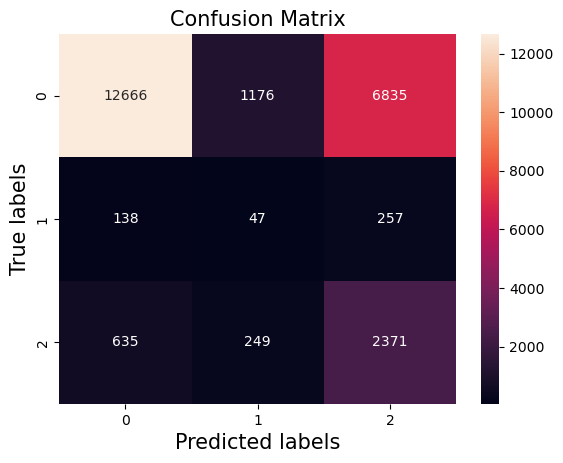

In [17]:
#Evaluate the model
y_valid_pred = clf.predict(X_valid)   # compute predicted labels for training data
multi_accuracy = accuracy_score(y_valid,y_valid_pred) # compute accuracy on the training set
print(f"Prediction accuracy: {100*multi_accuracy:.2f}%")
generate_confusion_matrix(y_valid, y_valid_pred)
plt.show()